# Solar radiation comparison



## Daily solar radiation

### Set up

In [1]:
# paths of weight files

path_weight_CaSR='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-CaSR_202108.nc'
path_weight_HRDPS25='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-continental2.5-hrdps.nc'
path_weight_HRDPS1='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-HRDPS-1km_202108.nc'
path_weight_HRDPS10='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-HRDPS-subsampled_202108.nc'

# Grid Regions
REGIONS = {
    "Central SoG":  (450, 500, 250, 300),
    "Juan de Fuca": (300, 365,  50, 100),
    "Haro Strait":  (280, 320, 210, 250),
    "Northern SoG": (650, 700, 140, 180),
    "Puget Sound":  (75,  125, 225, 280),
    "Pam Rocks":    (490, 510, 330, 350),
    "SandHeads":    (420, 440, 280, 300),
}


In [10]:

from pathlib import Path
import calendar
from datetime import date
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

YEAR = 2023
MONTHS = 3,6,9,12
REGION_NAME = "SandHeads"

OUTPUT_DIR = '/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_forcing_comparison/Analysis_solar/'
# When False, missing daily forcing files raise an error; True logs and skips them.
SKIP_MISSING_FILES = True

REGIONS = {
    "Central SoG":  (450, 500, 250, 300),
    "Juan de Fuca": (300, 365,  50, 100),
    "Haro Strait":  (280, 320, 210, 250),
    "Northern SoG": (650, 700, 140, 180),
    "Puget Sound":  (75,  125, 225, 280),
    "Pam Rocks":    (490, 510, 330, 350),
    "SandHeads":    (420, 440, 280, 300),
}

# Atmospheric *source* grid (y, x) shapes, daily file patterns and weights.
FORCINGS = {
    "CaSR": {
        "shape": (105, 70),
        "file_pattern": "/ocean/jqiu/forcings/CaSR/CaSR_y{year}m{month:02d}d{day:02d}.nc",
        "weights": "/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-CaSR_202108.nc",
    },
    "HRDPS25": {
        "shape": (230, 190),
        "file_pattern": "/results/forcing/atmospheric/continental2.5/nemo_forcing/hrdps_y{year}m{month:02d}d{day:02d}.nc",
        "weights": "/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-continental2.5-hrdps.nc",
    },
    "HRDPS1": {
        "shape": (1180, 1330),
        "file_pattern": "/ocean/jqiu/forcings/HRDPS_1km/HRDPS_1km_y{year}m{month:02d}d{day:02d}.nc",
        "weights": "/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-HRDPS-1km_202108.nc",
    },
    "HRDPS10": {
        "shape": (58, 48),
        "file_pattern": "/ocean/jqiu/forcings/HRDPS_subsampled/hrdps_subsampled_y{year}m{month:02d}d{day:02d}.nc",
        "weights": "/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-HRDPS-subsampled_202108.nc",
    },
}

j0, j1, i0, i1 = REGIONS[REGION_NAME]
assert 0 <= j0 < j1 and 0 <= i0 < i1
region_slices = {"y": slice(j0, j1), "x": slice(i0, i1)}
n_region_points = (j1 - j0) * (i1 - i0)

### Extract solar radiation


In [3]:
def load_region_weights(path, target_slices, forcing_shape):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Missing weights file: {path}")
    with xr.open_dataset(path) as ds:
        for k in range(1, 5):
            for prefix in ("src", "wgt"):
                var = f"{prefix}0{k}"
                if var not in ds:
                    raise KeyError(f"{var} is missing from {path}")
        # Ensure the entire region exists in the NEMO target grid.
        if ds.sizes["y"] < target_slices["y"].stop or ds.sizes["x"] < target_slices["x"].stop:
            raise ValueError(f"Region lies outside target grid in {path}")
        source = np.stack([
            ds[f"src0{k}"].isel(**target_slices).transpose("y", "x").values
            for k in range(1, 5)
        ]).reshape(4, -1)
        weights = np.stack([
            ds[f"wgt0{k}"].isel(**target_slices).transpose("y", "x").values
            for k in range(1, 5)
        ]).reshape(4, -1).astype(float)


    source = source.astype(np.int64) - 1
 
    n_source = np.prod(forcing_shape)
    invalid = (source < 0) | (source >= n_source)

    
    weights = np.where(invalid, 0.0, weights)
    source = np.where(invalid, 0, source)


    return source, weights

region_weights = {}
for forcing, config in FORCINGS.items():
    src, wgt = load_region_weights(config["weights"], region_slices, config["shape"])
    assert src.shape == (4, n_region_points)
    region_weights[forcing] = (src, wgt)
    print(f"{forcing}: {src.shape[1]} target ocean cells, weights loaded")


CaSR: 400 target ocean cells, weights loaded
HRDPS25: 400 target ocean cells, weights loaded
HRDPS1: 400 target ocean cells, weights loaded
HRDPS10: 400 target ocean cells, weights loaded


In [8]:
def timestamp_string(value):
    if isinstance(value, np.datetime64):
        return np.datetime_as_string(value, unit="s")
    if hasattr(value, "strftime"):
        return value.strftime("%Y-%m-%dT%H:%M:%S")
    raise ValueError(f"Unsupported timestamp: {value!r}")

def process_daily_file(path, source_shape, source_index, weights, expected_date):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(path)

    records = []

    with xr.open_dataset(path) as ds:
        var_name = "solar"

        if var_name not in ds:
            raise KeyError(f"{var_name} not found in {path}")

        var = ds[var_name]

        if not {"time_counter", "y", "x"}.issubset(var.dims):
            raise ValueError(f"Unexpected dims for {var_name}: {var.dims}")

        if (var.sizes["y"], var.sizes["x"]) != source_shape:
            raise ValueError(f"{var_name} grid shape mismatch in {path}")

        if "time_counter" not in ds.coords:
            raise ValueError(f"Missing time_counter coordinate: {path}")

        times = ds["time_counter"].values

        for t, time_value in enumerate(times):
            timestamp = timestamp_string(time_value)

            if timestamp[:10] != expected_date.isoformat():
                raise ValueError(f"Unexpected timestamp {timestamp} in {path}")

            # Extract solar radiation
            solar = (
                ds["solar"]
                .isel(time_counter=t)
                .transpose("y", "x")
                .values
                .ravel()
            )

            # Apply spatial interpolation weights
            solar_neighbors = solar[source_index]

            used = np.abs(weights) > 0

            valid = np.all(
                ~used | np.isfinite(solar_neighbors),
                axis=0
            )

            solar_grid = np.sum(
                np.where(used, solar_neighbors, 0.0) * weights,
                axis=0
            )

            solar_grid[~valid] = np.nan

            n_valid = int(np.isfinite(solar_grid).sum())

            records.append({
                "time": timestamp,
                "solar": float(np.nanmean(solar_grid)) if n_valid else np.nan,
                "n_valid": n_valid,
            })

    return records



In [11]:

# Extract
results = []
missing_files = []

for forcing, config in FORCINGS.items():
    src, wgt = region_weights[forcing]
    count = 0

    for month in MONTHS:
        n_days = calendar.monthrange(YEAR, month)[1]

        for day in range(1, n_days + 1):
            this_date = date(YEAR, month, day)

            daily_path = config["file_pattern"].format(
                year=YEAR,
                month=month,
                day=day
            )

            if not Path(daily_path).is_file():
                if not SKIP_MISSING_FILES:
                    raise FileNotFoundError(daily_path)

                missing_files.append(daily_path)
                continue

            daily_records = process_daily_file(
                daily_path,
                config["shape"],
                src,
                wgt,
                this_date
            )

            for record in daily_records:
                record.update({
                    "forcing": forcing,
                    "region": REGION_NAME,
                    "n_region_points": n_region_points
                })

            results.extend(daily_records)
            count += len(daily_records)

        print(f"{forcing}: {YEAR}-{month:02d} processed")

    print(f"{forcing}: {count} total time records processed")


if not results:
    raise RuntimeError(
        "No forcing records were processed. "
        "Check paths and selected year/months."
    )

df_long = (
    pd.DataFrame(results)
    .sort_values(["time", "forcing"])
    .reset_index(drop=True)
)

df_long["time"] = pd.to_datetime(df_long["time"])

df_wide = (
    df_long
    .pivot(index="time", columns="forcing", values="solar")
    .reset_index()
)

df_wide.columns.name = None

CaSR: 2023-03 processed
CaSR: 2023-06 processed
CaSR: 2023-09 processed
CaSR: 2023-12 processed
CaSR: 2928 total time records processed
HRDPS25: 2023-03 processed
HRDPS25: 2023-06 processed
HRDPS25: 2023-09 processed
HRDPS25: 2023-12 processed
HRDPS25: 2928 total time records processed
HRDPS1: 2023-03 processed
HRDPS1: 2023-06 processed
HRDPS1: 2023-09 processed
HRDPS1: 2023-12 processed
HRDPS1: 2856 total time records processed
HRDPS10: 2023-03 processed
HRDPS10: 2023-06 processed
HRDPS10: 2023-09 processed
HRDPS10: 2023-12 processed
HRDPS10: 2928 total time records processed


In [12]:
# save

save_path = OUTPUT_DIR + f"{REGION_NAME}_Solar.csv"

df_wide.to_csv(save_path, index=False)

print(f"Saved wide CSV: {save_path}")

Saved wide CSV: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_forcing_comparison/Analysis_solar/SandHeads_Solar.csv


### Scatter Plot

In [13]:
# paths

path_csv='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_forcing_comparison/Analysis_solar/SandHeads_Solar.csv'


DAILY MEAN SOLAR RADIATION STATISTICS
Reference: HRDPS2.5
Bias = Experiment - HRDPS2.5
Bias and RMSE units: W/m²

 Month Experiment     Bias    RMSE      R  p_value Significance  N_pairs
     3       CaSR  10.9859 22.8548 0.9394   0.0054           **       31
     3     HRDPS1  -4.7167 28.8320 0.8848   0.3965           ns       28
     3    HRDPS10  -0.6222  2.0426 0.9994   0.0900           ns       31
     6       CaSR -12.5528 43.6015 0.8589   0.1163           ns       30
     6     HRDPS1  -4.5584 22.0113 0.9673   0.2636           ns       30
     6    HRDPS10  -0.0862  1.2528 0.9999   0.7130           ns       30
     9       CaSR  -3.5000 22.8396 0.9468   0.4105           ns       30
     9     HRDPS1  -2.6874 14.0198 0.9774   0.3016           ns       30
     9    HRDPS10   0.1142  0.9875 0.9999   0.5356           ns       30
    12       CaSR   4.6685  9.2211 0.8823   0.0031           **       31
    12     HRDPS1   0.9761  6.4713 0.9356   0.4099           ns       31
    12   

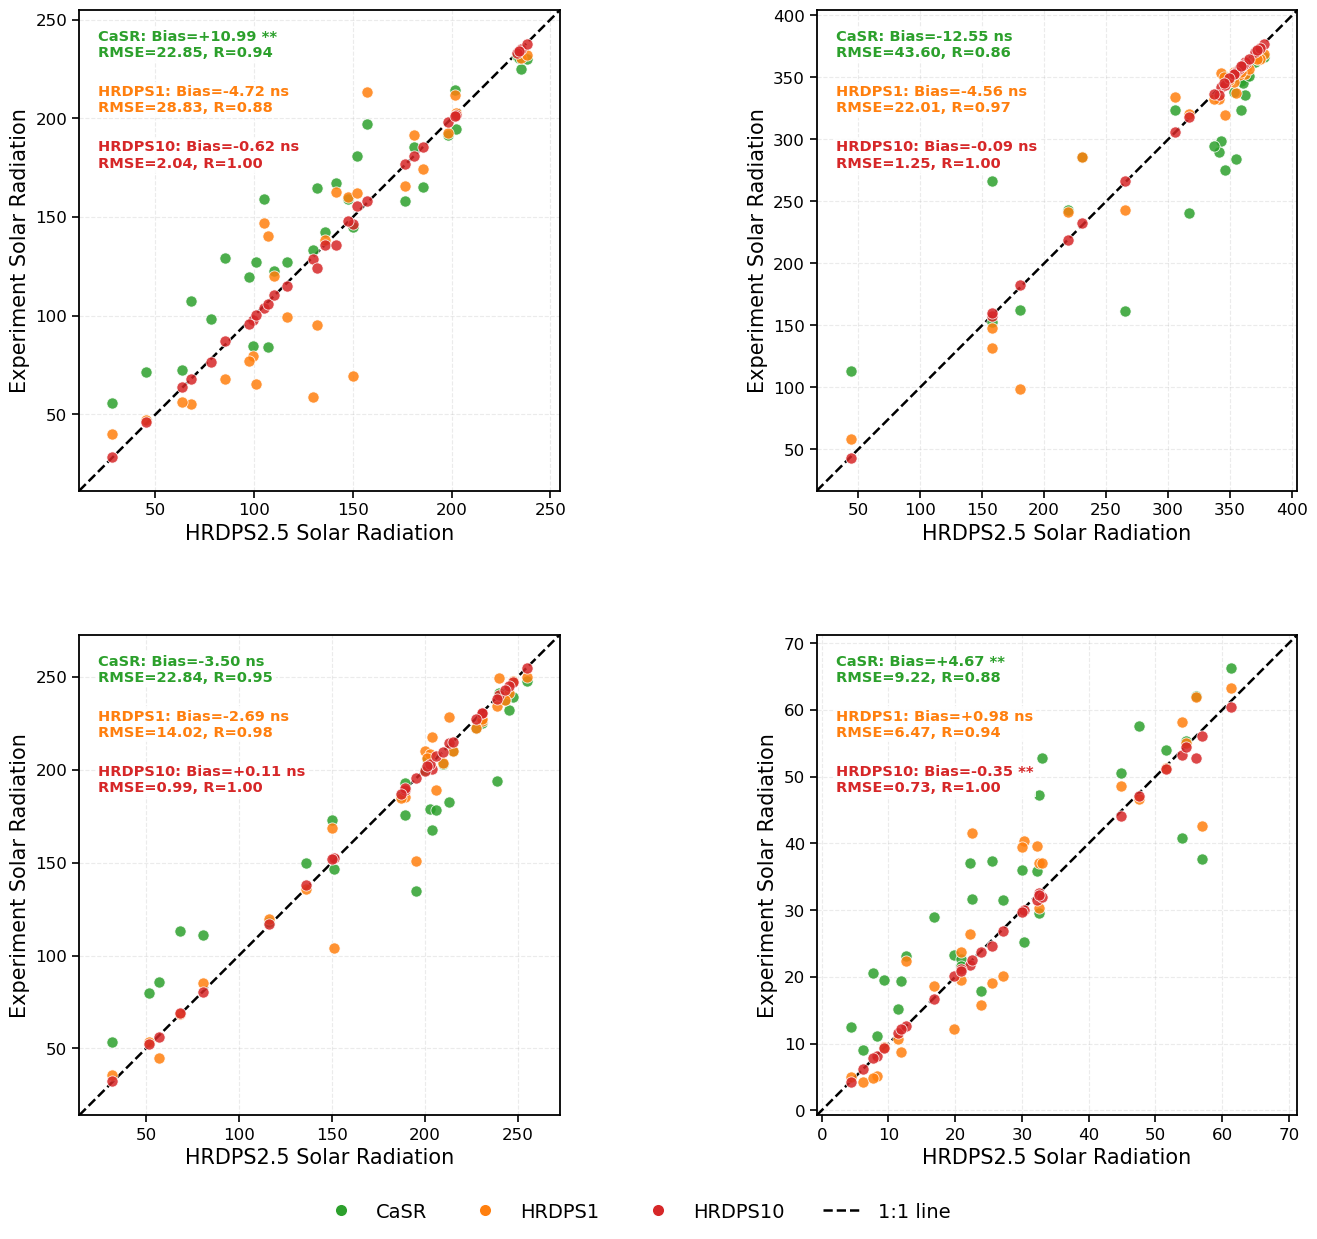

In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import ttest_rel, pearsonr



# Settings
REFERENCE = "HRDPS25"
MODELS = ["CaSR", "HRDPS1", "HRDPS10"]
MONTHS = [3, 6, 9, 12]

EXPERIMENT_COLORS = {
    "HRDPS25": "tab:blue",
    "HRDPS1": "tab:orange",
    "CaSR": "tab:green",
    "HRDPS10": "tab:red",
}

# Read CSV
df = pd.read_csv(path_csv)
df.columns = df.columns.str.strip()
df["time"] = pd.to_datetime(df["time"])

columns = [REFERENCE] + MODELS
df[columns] = df[columns].apply(
    pd.to_numeric, errors="coerce"
)

# Daily mean solar radiation
daily = (
    df.set_index("time")[columns]
    .resample("1D")
    .mean()
)

# Figure settings
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 14,
    "axes.labelsize": 15,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 13,
    "axes.linewidth": 1.3,
})

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 13),
    facecolor="white"
)

axes = axes.flatten()

stats_results = []

# Scatter plots
for ax, month in zip(axes, MONTHS):

    month_data = daily[
        (daily.index.year == 2023) &
        (daily.index.month == month)
    ]

    all_values = []

    for idx, model in enumerate(MODELS):

        paired = month_data[
            [REFERENCE, model]
        ].dropna()

        x = paired[REFERENCE].values
        y = paired[model].values

        n = len(x)

        if n == 0:
            continue

        # Scatter
        ax.scatter(
            x, y,
            s=65,
            alpha=0.85,
            color=EXPERIMENT_COLORS[model],
            edgecolors="white",
            linewidths=0.6,
            zorder=3,
        )

        all_values.extend(x)
        all_values.extend(y)

        # Statistics
        bias = np.mean(y - x)
        rmse = np.sqrt(np.mean((y - x) ** 2))

        if n >= 2:
            _, p_value = ttest_rel(y, x)
        else:
            p_value = np.nan

        if (
            n >= 2
            and np.std(x) > 0
            and np.std(y) > 0
        ):
            r, _ = pearsonr(x, y)
        else:
            r = np.nan

        if p_value < 0.001:
            sig = "***"
        elif p_value < 0.01:
            sig = "**"
        elif p_value < 0.05:
            sig = "*"
        else:
            sig = "ns"

        stats_results.append({
            "Month": month,
            "Experiment": model,
            "Bias": bias,
            "RMSE": rmse,
            "R": r,
            "p_value": p_value,
            "Significance": sig,
            "N_pairs": n,
        })

        # Statistics annotation
        stats_text = (
            f"{model}: "
            f"Bias={bias:+.2f} {sig}\n"
            f"RMSE={rmse:.2f}, R={r:.2f}"
        )

        ax.text(
            0.04,
            0.96 - idx * 0.115,
            stats_text,
            transform=ax.transAxes,
            fontsize=10.5,
            fontweight="semibold",
            color=EXPERIMENT_COLORS[model],
            va="top",
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.85,
                pad=2,
            ),
            zorder=10,
        )

    # 1:1 reference line
    if all_values:

        vmin = np.min(all_values)
        vmax = np.max(all_values)

        margin = 0.08 * (vmax - vmin)

        if margin == 0:
            margin = max(abs(vmax) * 0.05, 0.01)

        lims = [vmin - margin, vmax + margin]

        ax.plot(
            lims, lims,
            color="black",
            linestyle="--",
            linewidth=1.8,
            zorder=2,
        )

        ax.set_xlim(lims)
        ax.set_ylim(lims)

    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("HRDPS2.5 Solar Radiation")
    ax.set_ylabel("Experiment Solar Radiation")

    ax.tick_params(
        axis="both",
        width=1.2,
        length=5,
    )

    ax.grid(
        alpha=0.25,
        linestyle="--",
        linewidth=0.8,
    )

# Shared legend
legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markersize=9,
        markerfacecolor=EXPERIMENT_COLORS[model],
        markeredgecolor="white",
        label=model,
    )
    for model in MODELS
]

legend_handles.append(
    Line2D(
        [0], [0],
        color="black",
        linestyle="--",
        linewidth=1.8,
        label="1:1 line",
    )
)

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.025),
    ncol=4,
    frameon=False,
    fontsize=14,
)

plt.subplots_adjust(
    left=0.10,
    right=0.97,
    top=0.97,
    bottom=0.12,
    hspace=0.30,
    wspace=0.30,
)

# Print statistics
stats_df = pd.DataFrame(stats_results)

print("\nDAILY MEAN SOLAR RADIATION STATISTICS")
print("Reference: HRDPS2.5")
print("Bias = Experiment - HRDPS2.5")
print("Bias and RMSE units: W/m²\n")

print(
    stats_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

plt.show()



## How many hours of sunshine everyday?

In [ ]:
# paths

path_csv='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_forcing_comparison/Analysis_solar/SandHeads_Solar.csv'

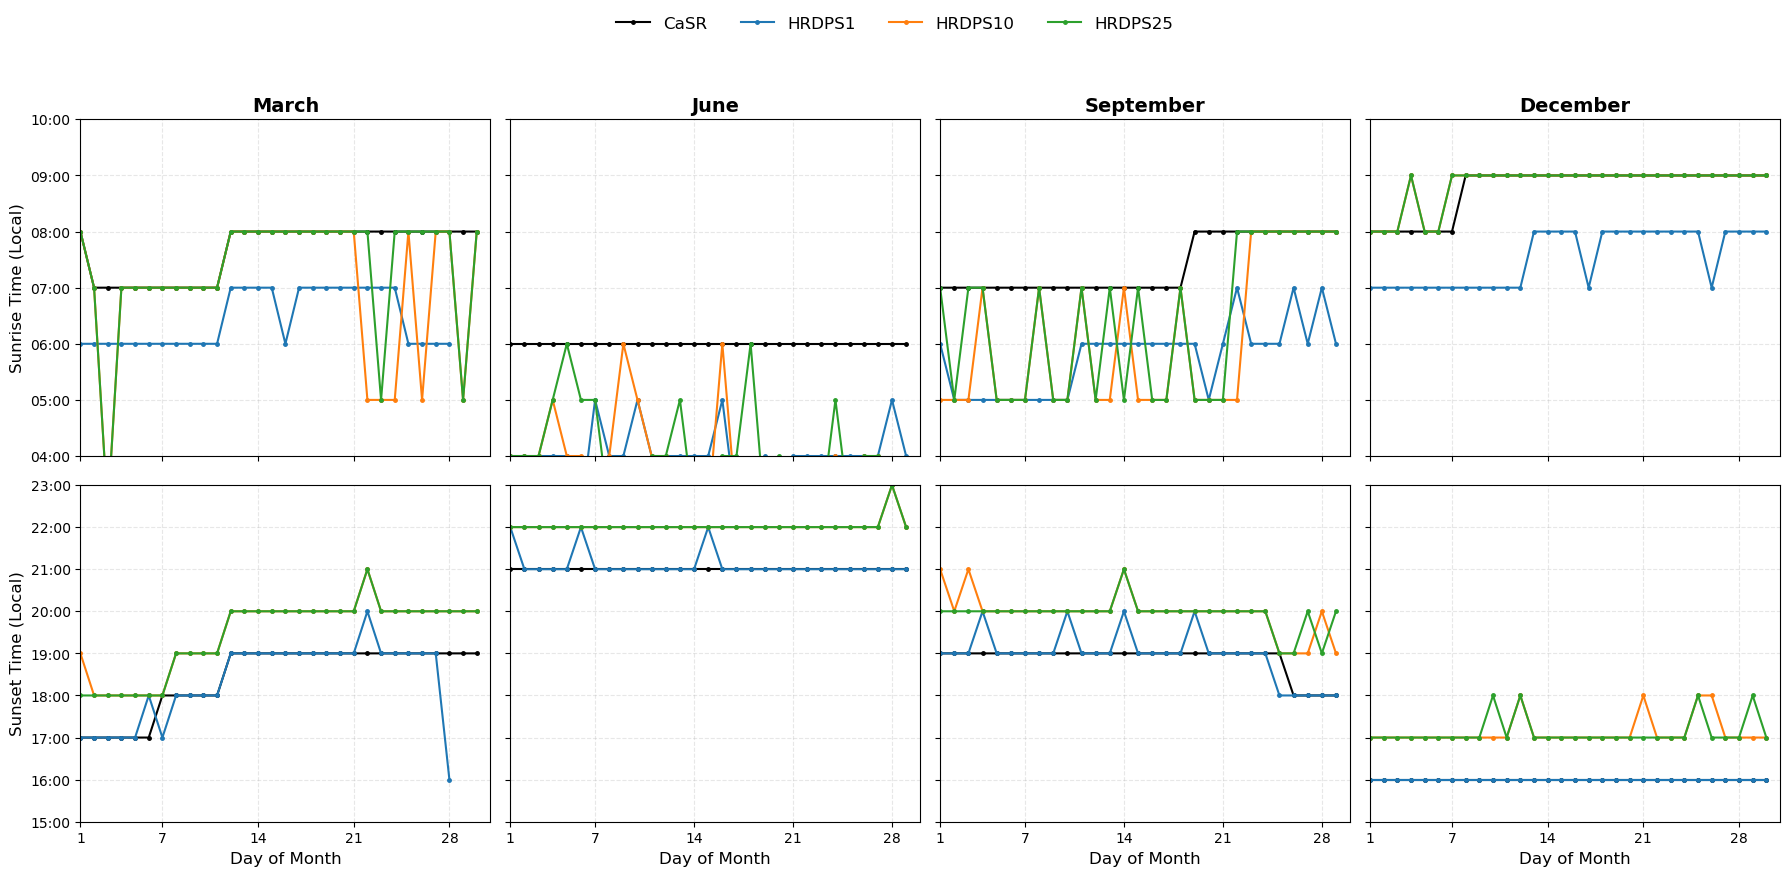

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import calendar

# set up

path_csv = '/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_forcing_comparison/Analysis_solar/SandHeads_Solar.csv'

models = ['CaSR', 'HRDPS1', 'HRDPS10', 'HRDPS25']
months = [3, 6, 9, 12]

# Radiation threshold (W/m²)
# Values <= threshold are considered nighttime
threshold = 0

# UTC to local time
TIME_IS_UTC = True
LOCAL_TZ = 'America/Vancouver'

colors = {
    'CaSR': 'black',
    'HRDPS1': 'tab:blue',
    'HRDPS10': 'tab:orange',
    'HRDPS25': 'tab:green'
}

# read

df = pd.read_csv(path_csv)
df['time'] = pd.to_datetime(df['time'])

if TIME_IS_UTC:
    df['local_time'] = (
        df['time']
        .dt.tz_localize('UTC')
        .dt.tz_convert(LOCAL_TZ)
    )
else:
    df['local_time'] = df['time']

df = df.sort_values('local_time').reset_index(drop=True)

df['date'] = df['local_time'].dt.date
df['month'] = df['local_time'].dt.month

df = df[df['month'].isin(months)].copy()

# daily variation

results = []

for date, group in df.groupby('date'):

    # Skip incomplete days at CSV boundaries
    hours = group['local_time'].dt.hour

    if hours.min() > 1 or hours.max() < 22:
        continue

    for model in models:

        # Select times with significant solar radiation
        daylight = group.loc[
            group[model] > threshold, 'local_time'
        ]

        if daylight.empty:
            continue

        # First and last daylight observations
        sunrise = daylight.iloc[0]
        sunset = daylight.iloc[-1]

        # Convert time to decimal hours
        sunrise_hour = (
            sunrise.hour
            + sunrise.minute / 60
            + sunrise.second / 3600
        )

        sunset_hour = (
            sunset.hour
            + sunset.minute / 60
            + sunset.second / 3600
        )

        results.append({
            'date': pd.Timestamp(date),
            'month': date.month,
            'day': date.day,
            'model': model,
            'sunrise': sunrise_hour,
            'sunset': sunset_hour
        })

result = pd.DataFrame(results)

if result.empty:
    raise ValueError(
        'No valid sunrise/sunset data found. '
        'Check the time zone and radiation threshold.'
    )

# visualize

fig, axes = plt.subplots(
    2, 4,
    figsize=(18, 8),
    sharey='row',
    sharex='col'
)

month_names = ['March', 'June', 'September', 'December']

for i, month in enumerate(months):

    month_data = result[result['month'] == month]

    for model in models:

        sub = month_data[
            month_data['model'] == model
        ].sort_values('day')

        # Sunrise (first row)
        axes[0, i].plot(
            sub['day'],
            sub['sunrise'],
            color=colors[model],
            marker='o',
            markersize=2.5,
            linewidth=1.5,
            label=model
        )

        # Sunset (second row)
        axes[1, i].plot(
            sub['day'],
            sub['sunset'],
            color=colors[model],
            marker='o',
            markersize=2.5,
            linewidth=1.5,
            label=model
        )

    axes[0, i].set_title(
        month_names[i],
        fontsize=14,
        fontweight='bold'
    )

    last_day = calendar.monthrange(2023, month)[1]

    for row in range(2):
        ax = axes[row, i]

        ax.set_xlim(1, last_day)
        ax.set_xticks([1, 7, 14, 21, 28])
        ax.grid(alpha=0.3, linestyle='--')
        ax.tick_params(labelsize=10)

    axes[1, i].set_xlabel('Day of Month', fontsize=12)



def hour_formatter(x, pos):
    hour = int(x)
    minute = int(round((x - hour) * 60))
    return f'{hour:02d}:{minute:02d}'

formatter = FuncFormatter(hour_formatter)

for ax in axes[:, 0]:
    ax.yaxis.set_major_formatter(formatter)

axes[0, 0].set_ylabel('Sunrise Time (Local)', fontsize=12)
axes[1, 0].set_ylabel('Sunset Time (Local)', fontsize=12)

# Adjust if necessary for your location
for ax in axes[0, :]:
    ax.set_ylim(4, 10)

for ax in axes[1, :]:
    ax.set_ylim(15, 23)

# Shared legend
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc='upper center',
    ncol=4,
    fontsize=12,
    frameon=False,
    bbox_to_anchor=(0.5, 1.1)
)

plt.tight_layout()

plt.show()




## See if there is pattern in different years

### Set up

In [1]:
# paths of weight files
from pathlib import Path
import calendar
from datetime import date

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt


YEARS = [2021, 2022, 2023, 2024]

MONTHS = [3]  # March only
# MONTHS = range(1, 13)  # Full years

REGION_NAME = "SandHeads"

OUTPUT_DIR = Path(
    "/home/jqiu/analysis-junqi/"
    "Analysis_Atmospheric_Forcing/"
    "Analysis_forcing_comparison/"
    "Analysis_solar/Data_2021_2024/"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SKIP_MISSING_FILES = True

REGIONS = {
    "Central SoG":  (450, 500, 250, 300),
    "Juan de Fuca": (300, 365, 50, 100),
    "Haro Strait":  (280, 320, 210, 250),
    "Northern SoG": (650, 700, 140, 180),
    "Puget Sound":  (75, 125, 225, 280),
    "Pam Rocks":    (490, 510, 330, 350),
    "SandHeads":    (420, 440, 280, 300),
}

j0, j1, i0, i1 = REGIONS[REGION_NAME]

assert 0 <= j0 < j1 and 0 <= i0 < i1

region_slices = {
    "y": slice(j0, j1),
    "x": slice(i0, i1)
}

n_region_points = (j1 - j0) * (i1 - i0)

print(f"Region: {REGION_NAME}")
print(f"Number of target grid cells: {n_region_points}")

Region: SandHeads
Number of target grid cells: 400


### Extract

In [6]:
WEIGHTS_DIR = Path(
    "/home/jqiu/analysis-junqi/"
    "Analysis_Atmospheric_Forcing/Data_weights/"
)

path_weight_CaSR = (
    WEIGHTS_DIR / "weights-CaSR_202108.nc"
)

path_weight_HRDPS25_old = '/ocean/jqiu/MOAD/grid/weights-gem2.5-gemlam_201702_pre22sep11.nc'

path_weight_HRDPS25_mid = '/ocean/jqiu/MOAD/grid/weights-gem2.5-gemlam_201702_22sep11onward.nc'

path_weight_HRDPS25_new = '/ocean/jqiu/MOAD/grid/weights-continental2.5-hrdps_202108_23feb23onward.nc'

path_HRDPS25_old = (
    "/results/forcing/atmospheric/GEM2.5/operational/"
    "ops_y{year}m{month:02d}d{day:02d}.nc"
)

path_HRDPS25_new = (
    "/results/forcing/atmospheric/continental2.5/nemo_forcing/"
    "hrdps_y{year}m{month:02d}d{day:02d}.nc"
)

FORCINGS = {
    "CaSR": {
        "shape": (105, 70),
        "file_pattern": (
            "/ocean/jqiu/forcings/CaSR/"
            "CaSR_y{year}m{month:02d}d{day:02d}.nc"
        ),
        "weights": path_weight_CaSR,
    },

    "HRDPS25_old": {
        "shape": None,
        "file_pattern": path_HRDPS25_old,
        "weights": path_weight_HRDPS25_old,
    },

    "HRDPS25_mid": {
        "shape": None,
        "file_pattern": path_HRDPS25_old,
        "weights": path_weight_HRDPS25_mid,
    },

    "HRDPS25_new": {
        "shape": (230, 190),
        "file_pattern": path_HRDPS25_new,
        "weights": path_weight_HRDPS25_new,
    },
}


def get_forcing_config(forcing, this_date):

    if forcing == "CaSR":
        return FORCINGS["CaSR"]

    if forcing == "HRDPS25":

        if this_date < date(2022, 9, 11):
            return FORCINGS["HRDPS25_old"]

        elif this_date < date(2023, 2, 23):
            return FORCINGS["HRDPS25_mid"]

        else:
            return FORCINGS["HRDPS25_new"]

    raise ValueError(f"Unknown forcing: {forcing}")

In [7]:
def load_region_weights(path, target_slices, forcing_shape):

    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(f"Missing weights file: {path}")

    with xr.open_dataset(path) as ds:

        for k in range(1, 5):
            for prefix in ("src", "wgt"):

                var = f"{prefix}0{k}"

                if var not in ds:
                    raise KeyError(f"{var} is missing from {path}")

        if (
            ds.sizes["y"] < target_slices["y"].stop
            or ds.sizes["x"] < target_slices["x"].stop
        ):
            raise ValueError(f"Region lies outside target grid: {path}")

        source = np.stack([
            ds[f"src0{k}"]
            .isel(**target_slices)
            .transpose("y", "x")
            .values
            for k in range(1, 5)
        ]).reshape(4, -1)

        weights = np.stack([
            ds[f"wgt0{k}"]
            .isel(**target_slices)
            .transpose("y", "x")
            .values
            for k in range(1, 5)
        ]).reshape(4, -1).astype(float)

    source = np.where(np.isfinite(source), source, 0)
    source = source.astype(np.int64) - 1

    n_source = np.prod(forcing_shape)

    invalid = (
        (source < 0)
        | (source >= n_source)
        | (~np.isfinite(weights))
    )

    invalid_target = np.any(
        invalid & (weights != 0),
        axis=0
    )

    weights = np.where(invalid, 0.0, weights)
    source = np.where(invalid, 0, source)

    weights[:, invalid_target] = 0.0

    return source, weights

In [8]:
def timestamp_string(value):

    if isinstance(value, np.datetime64):
        return np.datetime_as_string(value, unit="s")

    if hasattr(value, "strftime"):
        return value.strftime("%Y-%m-%dT%H:%M:%S")

    raise ValueError(f"Unsupported timestamp: {value!r}")


def process_daily_file(
    path,
    source_shape,
    source_index,
    weights,
    expected_date
):

    path = Path(path)

    records = []

    with xr.open_dataset(path) as ds:

        if "solar" not in ds:
            raise KeyError(f"solar not found in {path}")

        var = ds["solar"]

        if not {"time_counter", "y", "x"}.issubset(var.dims):
            raise ValueError(f"Unexpected dimensions: {var.dims}")

        if (var.sizes["y"], var.sizes["x"]) != source_shape:
            raise ValueError(f"Solar grid shape mismatch: {path}")

        times = ds["time_counter"].values

        # Read all solar radiation data for one day
        solar_all = (
            var.transpose("time_counter", "y", "x")
            .values
            .reshape(len(times), -1)
        )

        used = np.abs(weights) > 0

        # Target cells with valid interpolation weights
        has_weights = np.any(used, axis=0)

        for t, time_value in enumerate(times):

            timestamp = timestamp_string(time_value)

            if timestamp[:10] != expected_date.isoformat():
                raise ValueError(
                    f"Unexpected timestamp {timestamp} in {path}"
                )

            # Extract neighboring atmospheric grid cells
            solar_neighbors = solar_all[t, source_index]

            # Identify valid target grid cells
            valid = (
                has_weights
                & np.all(
                    ~used | np.isfinite(solar_neighbors),
                    axis=0
                )
            )

            # Apply spatial interpolation weights
            solar_grid = np.sum(
                np.where(used, solar_neighbors, 0.0) * weights,
                axis=0
            )

            solar_grid[~valid] = np.nan

            n_valid = int(np.isfinite(solar_grid).sum())

            # Regional spatial mean
            records.append({
                "time": timestamp,
                "solar": (
                    float(np.nanmean(solar_grid))
                    if n_valid else np.nan
                ),
                "n_valid": n_valid,
            })

    return records

In [10]:
results = []
missing_files = []
region_weights = {}

FORCING_NAMES = ["CaSR", "HRDPS25"]

for forcing in FORCING_NAMES:

    count = 0

    for year in YEARS:

        year_count = 0

        for month in MONTHS:

            n_days = calendar.monthrange(year, month)[1]

            month_count = 0

            for day in range(1, n_days + 1):

                this_date = date(year, month, day)

                # Select forcing configuration based on date
                config = get_forcing_config(forcing, this_date)

                daily_path = Path(
                    config["file_pattern"].format(
                        year=year,
                        month=month,
                        day=day
                    )
                )

                # Check daily forcing file
                if not daily_path.is_file():

                    if not SKIP_MISSING_FILES:
                        raise FileNotFoundError(daily_path)

                    missing_files.append({
                        "forcing": forcing,
                        "date": this_date.isoformat(),
                        "path": str(daily_path)
                    })

                    continue

                # Determine source grid shape
                weight_path = config["weights"]

                if weight_path not in region_weights:

                    with xr.open_dataset(daily_path) as ds:

                        source_shape = (
                            ds["solar"].sizes["y"],
                            ds["solar"].sizes["x"]
                        )

                    if (
                        config["shape"] is not None
                        and source_shape != config["shape"]
                    ):
                        raise ValueError(
                            f"Unexpected grid shape: {source_shape}"
                            f" in {daily_path}"
                        )

                    src, wgt = load_region_weights(
                        weight_path,
                        region_slices,
                        source_shape
                    )

                    assert src.shape == (4, n_region_points)

                    region_weights[weight_path] = (
                        src,
                        wgt,
                        source_shape
                    )

                    

                # Retrieve cached weights
                src, wgt, source_shape = region_weights[weight_path]

                # Extract daily solar radiation
                daily_records = process_daily_file(
                    daily_path,
                    source_shape,
                    src,
                    wgt,
                    this_date
                )

                for record in daily_records:

                    record.update({
                        "forcing": forcing,
                        "region": REGION_NAME,
                        "n_region_points": n_region_points
                    })

                results.extend(daily_records)

                month_count += len(daily_records)
                year_count += len(daily_records)
                count += len(daily_records)

            print(
                f"{forcing}: {year}-{month:02d} processed, "
                f"{month_count} time records"
            )

        print(
            f"{forcing}: {year} completed, "
            f"{year_count} time records"
        )

    print(f"{forcing}: {count} total time records")
    print("-" * 60)


if not results:

    raise RuntimeError(
        "No forcing records were processed. "
        "Check paths and selected years/months."
    )

CaSR: 2021-03 processed, 744 time records
CaSR: 2021 completed, 744 time records
CaSR: 2022-03 processed, 744 time records
CaSR: 2022 completed, 744 time records
CaSR: 2023-03 processed, 744 time records
CaSR: 2023 completed, 744 time records
CaSR: 2024-03 processed, 744 time records
CaSR: 2024 completed, 744 time records
CaSR: 2976 total time records
------------------------------------------------------------
HRDPS25: 2021-03 processed, 744 time records
HRDPS25: 2021 completed, 744 time records
HRDPS25: 2022-03 processed, 744 time records
HRDPS25: 2022 completed, 744 time records
HRDPS25: 2023-03 processed, 744 time records
HRDPS25: 2023 completed, 744 time records
HRDPS25: 2024-03 processed, 744 time records
HRDPS25: 2024 completed, 744 time records
HRDPS25: 2976 total time records
------------------------------------------------------------


In [11]:
df_long = (
    pd.DataFrame(results)
    .sort_values(["time", "forcing"])
    .reset_index(drop=True)
)

df_long["time"] = pd.to_datetime(df_long["time"])


df_wide = (
    df_long
    .pivot(
        index="time",
        columns="forcing",
        values="solar"
    )
    .reindex(columns=FORCING_NAMES)
    .reset_index()
)

df_wide.columns.name = None


# Output filenames
month_tag = "-".join(f"{m:02d}" for m in MONTHS)

file_prefix = (
    f"solar_{REGION_NAME.replace(' ', '_')}_"
    f"{min(YEARS)}_{max(YEARS)}_m{month_tag}"
)


path_wide = OUTPUT_DIR / f"{file_prefix}.csv"



# Save results

df_wide.to_csv(path_wide, index=False)




### Visualize

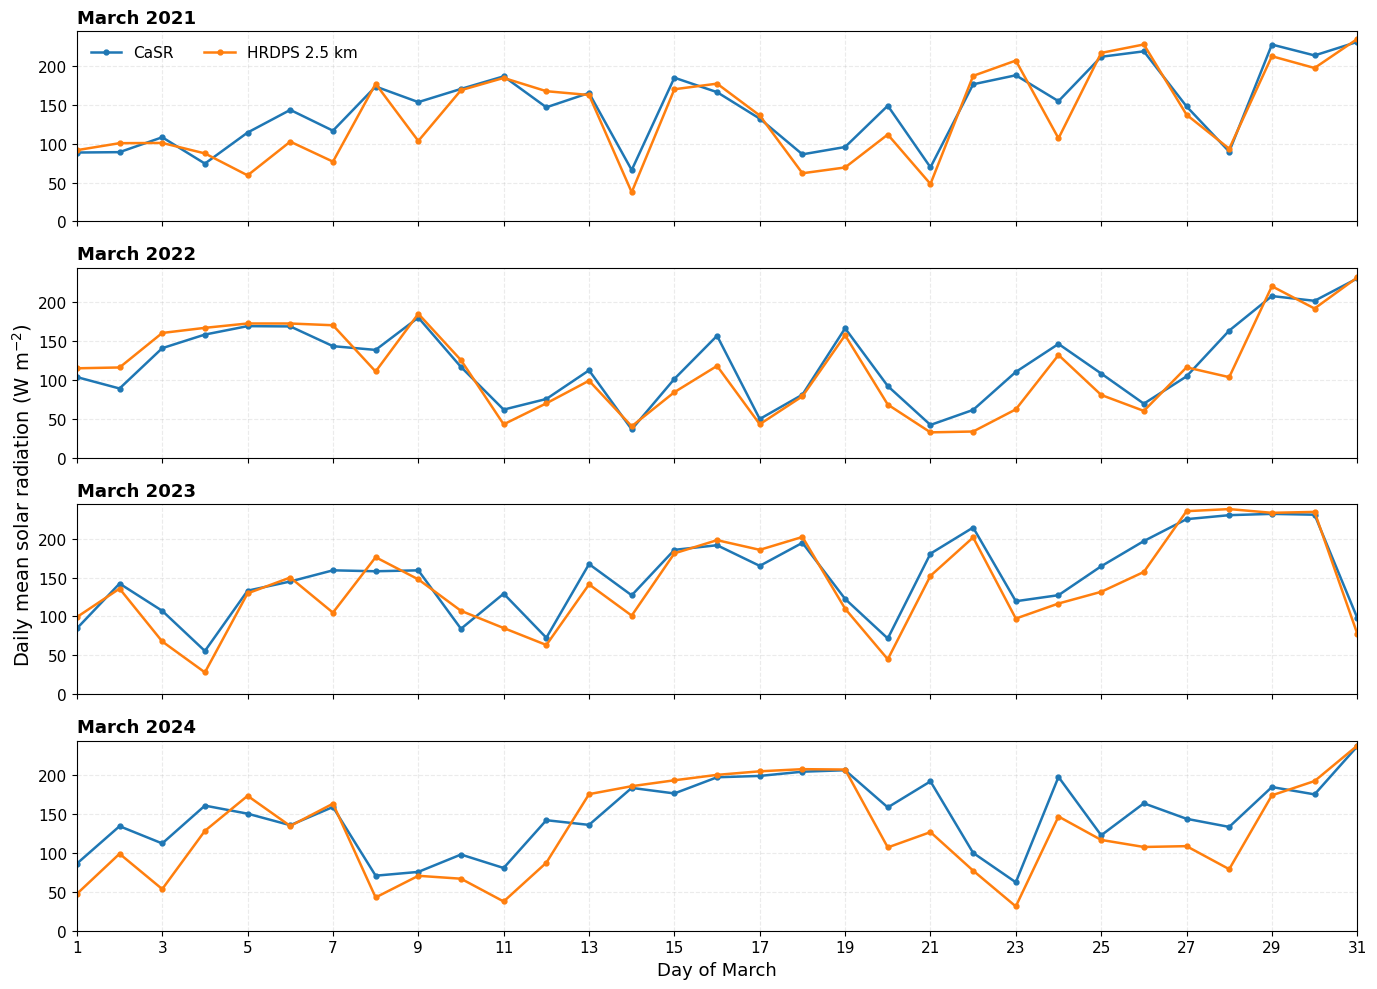

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Read data 

path = Path(
    "/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/"
    "Analysis_forcing_comparison/Analysis_solar/Data_2021_2024/"
    "solar_SandHeads_2021_2024_m03.csv"
)

df = pd.read_csv(path, parse_dates=["time"])

df = df.set_index("time").sort_index()

YEARS = [2021, 2022, 2023, 2024]
FORCINGS = ["CaSR", "HRDPS25"]

# daily mean 

df_daily = df[FORCINGS].resample("D").mean()

# March only
df_daily = df_daily[df_daily.index.month == 3]

# Plot 

fig, axes = plt.subplots(
    4, 1,
    figsize=(14, 10),
    sharex=True,
    sharey=True
)

colors = {
    "CaSR": "tab:blue",
    "HRDPS25": "tab:orange"
}

labels = {
    "CaSR": "CaSR",
    "HRDPS25": "HRDPS 2.5 km"
}

for i, (ax, year) in enumerate(zip(axes, YEARS)):

    df_year = df_daily[df_daily.index.year == year]

    for forcing in FORCINGS:

        ax.plot(
            df_year.index.day,
            df_year[forcing],
            color=colors[forcing],
            label=labels[forcing],
            linewidth=1.8,
            marker="o",
            markersize=3.5
        )

    ax.set_title(
        f"March {year}",
        loc="left",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlim(1, 31)
    ax.set_ylim(bottom=0)
    ax.set_xticks(np.arange(1, 32, 2))

    ax.grid(True, linestyle="--", alpha=0.25)
    ax.tick_params(axis="both", labelsize=11)

    # ax.spines["top"].set_visible(False)
    # ax.spines["right"].set_visible(False)

    if i == 0:
        ax.legend(
            loc="upper left",
            frameon=False,
            fontsize=11,
            ncol=2
        )

# Common axis labels
fig.supylabel(
    r"Daily mean solar radiation (W m$^{-2}$)",
    fontsize=14
)

axes[-1].set_xlabel("Day of March", fontsize=13)



plt.tight_layout()

plt.show()

In [16]:
from scipy.stats import ttest_rel, pearsonr

stats_results = []

for year in YEARS:

    # Select paired daily mean data
    df_year = df_daily.loc[
        (df_daily.index.year == year) &
        (df_daily.index.month == 3),
        ["CaSR", "HRDPS25"]
    ].dropna()

    casr = df_year["CaSR"].values
    hrdps = df_year["HRDPS25"].values

    n = len(df_year)

    if n < 2:
        continue

    # Difference: HRDPS25 - CaSR
    diff = hrdps - casr

    # RMSE
    rmse = np.sqrt(np.mean(diff**2))

    # Mean bias
    bias = np.mean(diff)

    # Mean absolute error
    mae = np.mean(np.abs(diff))

    # Pearson correlation
    r, p_corr = pearsonr(casr, hrdps)

    # Paired t-test
    t_stat, p_value = ttest_rel(hrdps, casr)

    # Statistical significance
    if p_value < 0.001:
        sig = "***"
    elif p_value < 0.01:
        sig = "**"
    elif p_value < 0.05:
        sig = "*"
    else:
        sig = "ns"

    stats_results.append({
        "Year": year,
        "N": n,
        "CaSR_mean": np.mean(casr),
        "HRDPS25_mean": np.mean(hrdps),
        "Bias": bias,
        "p_value": p_value,
        "Significance": sig
    })

df_stats = pd.DataFrame(stats_results)

display(df_stats.round(4))



,Year,N,CaSR_mean,HRDPS25_mean,Bias,p_value,Significance
0,2021,31,146.2931,135.8679,-10.4252,0.0116,*
1,2022,31,122.3061,115.0347,-7.2714,0.0571,ns
2,2023,31,150.8055,139.8196,-10.9859,0.0054,**
3,2024,31,147.6683,128.4896,-19.1787,0.0007,***
